# **언어 모델과 생성 모델**

<p align="right">15기 손영현</p>

---

## **1. NLP와 언어 모델**

### (1) NLP (Natural Language Processing)
- 인간이 쓰는 자연어를 컴퓨터가 분석·이해·생성할 수 있도록 하는 AI 기술
- 컴퓨터는 자연어의 의미를 직접 이해하지 못하므로, <mark style="background-color:#D6EEFF">언어를 **숫자(벡터) 형태로 변환**해서 단어 간 관계와 문맥을 분석함</mark>

#### [자연어 vs 프로그래밍 언어]
- 자연어: 사람 간 의사소통용 언어, **일대다 대응** → 유연하지만 모호함
- 프로그래밍 언어: 컴퓨터에 명령을 내리기 위한 언어, **일대일 대응** → 명확하고 엄격함

#### [자연어의 특징]
- **이산적 데이터**: 단어·문자 같은 구분된 기호로 이루어짐 → 벡터로 바꾸는 임베딩이 필요
- **순차적 데이터**: 단어 순서에 따라 의미가 달라짐 → 앞뒤 문맥을 보는 모델(RNN, Transformer 등) 필요
- **중의성과 모호성**: 하나의 단어가 여러 의미를 가짐 (ex. 배: 신체/과일/선박) → 문맥 전체를 봐야 함
- **희소성**: 단어 조합이 너무 다양해서 모든 표현을 학습할 수 없음 → 안 본 표현도 확률적으로 추론해야 함
- **가변성과 진화**: 신조어, 줄임말 등 언어가 계속 변함 → 고정 규칙보다 데이터로 패턴을 학습하는 방식이 필요

#### [NLP의 처리 단계]

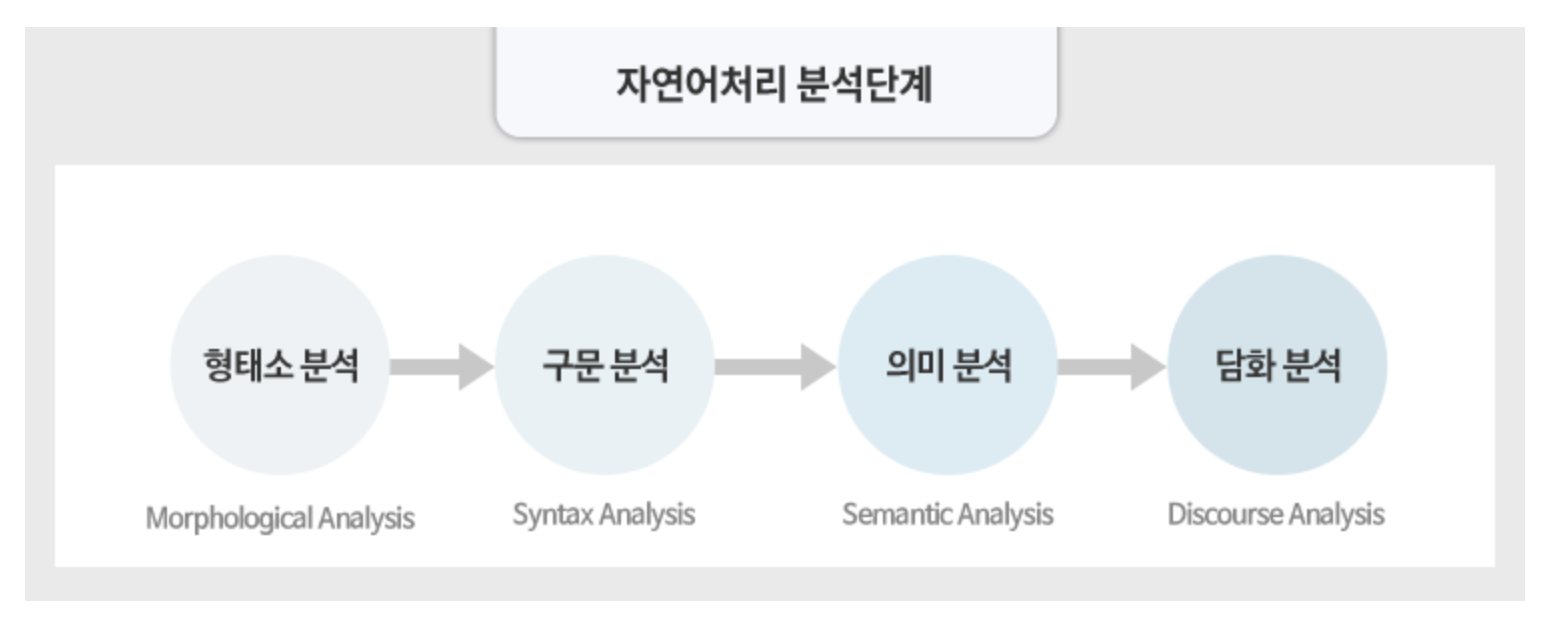

1. 형태소 분석: 문장을 형태소 단위로 나누고 품사 분석 (ex. 나/대명사 + 는/조사 + 학교/명사 …)
2. 구문 분석: 단어들의 문법적 관계 파악 (주어, 목적어, 서술어)
3. 의미 분석: 문맥에 맞는 의미 파악 (ex. "은행에서 돈을 찾았다" → 금융기관)
4. 담화 분석: 여러 문장 사이의 관계 파악 (ex. '그'가 누구를 가리키는지)

- 활용 분야: 기계 번역, 감성 분석, 텍스트 분류(스팸 탐지), 문서 요약, 질의응답·챗봇

### (2) 언어 모델
- <mark style="background-color:#D6EEFF">단어(토큰)의 등장 확률을 예측해서 문장이 얼마나 자연스러운지 판단하는 모델</mark>
- 쉽게 말하면 **인간이 말하고 쓰는 방식을 모방하는 시스템**
- 앞 문맥을 보고 다음 단어를 예측함
    - ex. "나는 아침에 밥을 ___" → 먹었다(80%) / 마셨다(15%) / 달렸다(5%)
- 학습 방식에 따라 **통계적 언어 모델(SLM)** / **신경망 언어 모델(NLM)** 으로 구분됨

---

## **2. 통계적 언어 모델 (SLM)**

### (1) Statistical Language Model
- **분포 가설**에 근거함
    - 분포 가설: <mark style="background-color:#D6EEFF">비슷한 문맥에서 등장하는 단어는 비슷한 의미를 가질 가능성이 높다는 가설</mark>
    - ex. "아침에 **커피**를 마셨다" / "아침에 **차**를 마셨다" → 커피와 차는 의미적으로 가까움
    - 이후 임베딩 기술의 이론적 기반이 됨
- **조건부 확률**: 앞 단어들이 주어졌을 때 다음 단어가 나올 확률
    - ex. P(갔다 | 나는 학교에) > P(먹었다 | 나는 학교에)
- **카운트 기반**: 학습 데이터에서 특정 문맥 다음에 어떤 단어가 몇 번 나왔는지 세서 확률 계산
    - ex. "나는 학교에" 100번 중 갔다 70번 → 70%

#### [한계: 희소 문제 (Sparsity Problem)]
- 가능한 단어 조합이 너무 많아서, 학습 데이터에 거의/아예 안 나온 표현이 생김
- <mark style="background-color:#D6EEFF">한 번도 안 나온 조합은 **확률이 0**이 됨</mark>
- ex. "나는 학교에 순간이동했다" → 문법적으로 가능한 문장인데도 확률 0
- → 희소 문제를 완화할 새로운 방법이 필요해짐

### (2) N-gram
#### [등장 배경]
- SLM은 문장이 길어질수록 문제가 생김
    - 데이터 희소성: 고려할 단어 조합이 많아질수록 데이터에 없는 조합이 늘어남
    - 계산 복잡성: 앞의 모든 단어를 고려하면 계산·저장 비용이 너무 큼
- → 앞의 모든 단어 대신 **직전 N-1개 단어만** 보자는 아이디어

#### [정의]
- 연속된 N개의 단어 묶음, 직전 N-1개 단어로 다음 단어를 예측하는 통계적 언어 모델
- uni: 1개씩, bi: 2개씩, tri: 3개씩, … N: N개씩
- ex. 4-gram으로 "An adorable little boy is spreading ___" 예측
    - 직전 3개인 'boy is spreading'만 보고, 그 뒤에 자주 나온 단어로 예측 (앞부분은 무시됨)

#### [SLM과의 관계]
- 둘 다 빈도와 조건부 확률로 다음 단어를 예측한다는 점은 같음
- SLM은 앞의 모든 단어를 조건으로 두고, N-gram은 N-1개로 제한함
- → N-gram은 별개의 모델이라기보다 **SLM의 계산을 단순화한 형태**

#### [한계]
- **희소 문제**: N이 커질수록 단어 조합 수가 급격히 늘어나서 데이터에서 찾기 어려워짐 (없으면 확률 0)
- **문맥 제한**: 직전 N-1개만 보니까 멀리 떨어진 단어 간 관계를 못 잡음
- → <mark style="background-color:#D6EEFF">N을 키우면 희소 문제, 줄이면 문맥 제한이 생기는 트레이드오프</mark>

### (3) Perplexity (PPL)
- 언어 모델이 문장을 예측할 때 얼마나 **혼란스러워하는지(perplexed)** 를 수치로 나타낸 지표
- <mark style="background-color:#D6EEFF">PPL이 **낮을수록** 실제 단어를 잘 예측함 (좋은 모델)</mark>
- 특징
    - 문장 W가 학습 데이터에 희소하게 나올수록 예측이 어려워서 PPL이 높아지는 경향
    - 예측하기 쉬운 단어가 추가되면 평균 난이도가 낮아져 PPL이 감소할 수 있음 (단, 항상 그런 건 아님)
- SLM뿐 아니라 NLM 성능 평가에도 쓰임
    - ex. 같은 평가 데이터에서 SLM: 80, NLM: 25 → NLM이 더 잘 예측

---

## **3. 신경망 언어 모델 (NLM)**

- 배경: SLM의 한계(희소 문제, 문맥 제한)를 인공 신경망으로 완화하기 위해 등장
- 핵심 키워드: **임베딩**
    - 단어를 연속적인 숫자 벡터로 바꿔서, 벡터 공간의 한 점으로 표현
    - <mark style="background-color:#D6EEFF">의미가 비슷한 단어는 벡터 공간에서 가까이 위치함</mark> (ex. moon, mars, nasa끼리 / god, church, bible끼리)
    - 덕분에 학습 데이터에 없던 표현도 비슷한 단어를 통해 **일반화** 가능

| 구분 | 통계적 언어 모델 (SLM) | 신경망 언어 모델 (NLM) |
|---|---|---|
| 학습 방식 | 단어 등장 빈도로 확률 계산 | 신경망 가중치 학습 |
| 단어 표현 | 개별 기호 | 연속적인 벡터 |
| 의미적 관계 | 반영 어려움 | 임베딩으로 유사성 학습 |
| 희소 문제 | 안 본 조합은 확률 0 | 유사 단어로 확률 추론 가능 |
| 문맥 처리 | N-gram은 N-1개만 | 구조에 따라 긴 문맥도 가능 (RNN, LSTM, Transformer) |
| 계산 비용 | 낮음 | 학습에 연산 자원 많이 필요 |

---

## **4. 딥러닝 기반 언어 모델**

### (1) Transformer의 등장
#### [RNN, LSTM의 한계]
- 장기 의존성 문제: 문장이 길어질수록 앞부분 정보를 유지하기 어려움
- 기울기 소실 문제: 역전파 과정에서 기울기가 점점 작아져 앞부분이 충분히 학습되지 않음
- 순차 처리의 비효율성: 순서대로 처리해야 해서 병렬 연산이 안 되고 학습이 느림

#### [Transformer]
- 2017년 Google의 *Attention Is All You Need* 논문에서 제안
- **Self-Attention**으로 단어 간 관계와 장거리 문맥을 효과적으로 학습
- **병렬 처리** + **위치 인코딩**으로 학습 효율을 높이고 단어 순서 정보도 반영
- → <mark style="background-color:#D6EEFF">RNN, LSTM의 한계를 완화했고, 이후 BERT·GPT 등 현대 언어 모델의 기반이 됨</mark>

#### [Transformer의 구조]
- 임베딩 및 위치 인코딩: 문장을 토큰으로 나눠 벡터로 바꾸고, 순환 구조가 없으니 위치 정보를 더해 순서를 구분
- 인코더
    - Self-Attention: 각 단어가 다른 단어들과 얼마나 관련 있는지 계산해서 문맥 파악
    - Feed Forward Network: 어텐션 결과를 변환해서 더 풍부한 특징 학습
    - 여러 층을 쌓아 문장 의미를 정교하게 학습
- 디코더
    - Masked Self-Attention: 미래 단어는 가리고 이전에 생성한 단어만 참고
    - Cross-Attention: 인코더 출력을 참고해서 입력 문장과 출력 문장 사이의 관계 학습
    - Feed Forward Network → 다음 단어 예측에 활용
- ex. 번역 "I am a student" → 인코더가 문맥 표현 생성 → 디코더가 'Je' → 'suis' → 'étudiant' 순서로 생성 → "Je suis étudiant"

### (2) BERT
- <mark style="background-color:#D6EEFF">Transformer **인코더 구조 기반**으로, 문장의 **양방향 문맥**을 학습해서 언어의 의미를 이해하는 모델</mark>
    - B (Bidirectional): 앞뒤 문맥을 모두 고려
    - ER (Encoder Representations): 인코더로 문맥이 반영된 단어 벡터 생성
    - T (from Transformers): 트랜스포머 인코더 구조 기반

#### [특징]
- 양방향: 앞 단어뿐 아니라 뒤 단어까지 함께 고려 → 단어 의미를 더 정확히 파악
- Transformer 기반: 인코더만 사용, Self-Attention으로 단어 간 관계 분석
- 사전학습 + 파인튜닝: 대량의 텍스트로 일반적인 언어 구조를 먼저 배우고, 특정 작업 데이터로 추가 학습

#### [처리 과정]
1. 토큰화: 문장을 토큰으로 나누고 `[CLS]`, `[SEP]` 같은 특수 토큰 추가
2. 임베딩: 토큰의 의미, 위치, 문장 구분 정보를 반영해서 벡터로 변환
3. 인코더: 여러 층의 Self-Attention을 거치며 문맥이 반영된 벡터 생성
4. 출력 및 활용: 문장 분류, 감성 분석, 질의응답 등 **문장 이해** 작업에 활용

#### [사전 학습]
- 정답 레이블 없이 텍스트 자체로 학습 가능
- **MLM (Masked Language Model)**: 빈칸 채우기
    - 문장 일부 토큰을 `[MASK]`로 가리고, 앞뒤 문맥으로 원래 토큰을 예측
    - ex. "How are `[MASK]` doing today" → 앞의 'How are'와 뒤의 'doing today'를 함께 보고 'you' 예측
    - 효과: 양방향 문맥 이해 능력 향상, 같은 단어도 문맥에 따라 달라지는 의미 학습

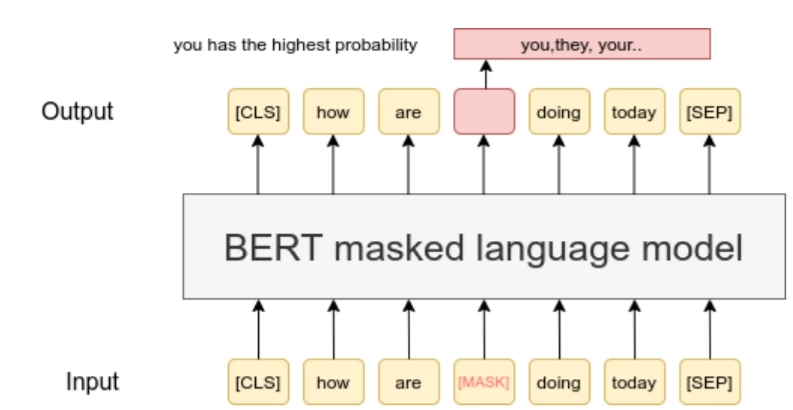

- **NSP (Next Sentence Prediction)**: 다음 문장 예측
    - 문장 A, B를 주고 B가 실제로 A 다음 문장이면 `IsNext`, 무작위 문장이면 `NotNext`로 분류
    - 효과: 두 문장 사이의 연결 관계 학습 → 문장 쌍 분류, 자연어 추론, 질의응답에 활용

#### [BERT 이후 모델]
- RoBERTa: BERT 구조는 그대로, NSP를 빼고 Dynamic Masking(마스킹 위치를 계속 바꿈) 적용 + 더 많은 데이터·큰 배치·긴 학습으로 성능 향상
- ALBERT: 임베딩 차원 축소, 층 간 파라미터 공유로 파라미터 수를 크게 줄인 경량 모델, NSP 대신 문장 순서 예측(SOP) 사용

### (3) GPT
- Transformer **디코더 기반**으로 이전 단어들을 보고 다음 단어를 예측해서 텍스트를 생성하는 모델
- 구조
    - 인코더가 없으니 Cross-Attention도 사용하지 않음
    - Masked Self-Attention: 이전 토큰만 보고 다음 토큰 예측 (디코더의 핵심)
    - Feed Forward Network
- → <mark style="background-color:#D6EEFF">이전 토큰으로 다음 토큰을 순차적으로 예측하는 **자기회귀** 방식</mark>
- GPT-3부터는 파인튜닝 없이 프롬프트의 지시와 예시만으로 작업을 수행하는 **In-Context Learning** 가능
    - Zero-shot: 예시 없이 지시만
    - One-shot: 예시 1개
    - Few-shot: 예시 몇 개

### (4) LLM (Large Language Model)
- 방대한 텍스트 데이터와 대규모 신경망으로 인간의 언어를 이해하고 생성하도록 학습된 모델
- 대부분 Transformer 기반, 생성뿐 아니라 번역·요약·질의응답 등 다양한 작업 수행
- ex. GPT 계열(ChatGPT), LLaMA, Claude, Gemini 등

#### [작동 방식]
- 학습
    - 사전학습: 대량의 텍스트로 다음 토큰 예측을 반복하며 언어 구조와 문맥 학습
    - 파인튜닝: 특정 작업·목적에 맞는 데이터로 추가 학습
    - 예측값과 정답의 차이를 줄이도록 가중치 업데이트
- 예측: 입력을 토큰화·벡터화 → Attention으로 토큰 간 관계 분석 → 다음 토큰 확률 계산 → 확률 높은 단어를 순서대로 이어 붙여 응답 생성

#### [LLM이 GPT 방식을 쓰는 이유]
- BERT는 입력 문장을 **이해**하는 데 중점, GPT는 다음 토큰을 예측해 **생성**하는 데 특화
- → 질문에 새로운 문장으로 답해야 하는 대화형 LLM에는 자기회귀 방식의 GPT 계열 구조가 주로 쓰임

#### [한계]
- 환각 현상 (Hallucination): 사실과 다르거나 없는 정보를 그럴듯하게 생성
    - 확률 기반으로 다음 토큰을 고르기 때문에 사실 여부가 보장되지 않음
    - <mark style="background-color:#D6EEFF">RAG, 외부 검색, 검증 등으로 완화할 수 있지만 **완전히 해결된 문제는 아님**</mark>
- 높은 학습·업데이트 비용: 사전학습에 막대한 자원이 들고, 새 정보를 넣으려면 추가 학습이 필요함 → 최신 정보가 자동 반영되지 않음

### (5) RAG (Retrieval Augmented Generation)
- <mark style="background-color:#D6EEFF">**외부 지식 검색 + LLM의 생성 능력**을 결합해서 답변의 정확성과 최신성을 높이는 기술</mark>
- 배경: LLM은 학습 시점까지의 지식만 알고, 그 이후 정보는 답할 수 없음

#### [구조]
1. 질의 인코더 (Query Encoder): 사용자 질문을 임베딩 모델로 벡터화
2. 지식 검색기 (Knowledge Retriever): 벡터 DB에서 질문 벡터와 유사도가 높은 문서를 검색해서 LLM에 전달
3. 지식 증강 생성기 (Knowledge-Augmented Generator): 질문 + 검색된 문서를 LLM에 같이 넣어 최종 답변 생성

#### [장점]
- 최신 정보 반영: 재학습 없이 외부 DB나 최신 문서를 검색해서 활용
- 정확성 향상: 검색한 자료를 근거로 답하니까 환각 현상 완화, 신뢰성 ↑

#### [CAG (Credibility-aware Generation)]
- RAG의 한계: 질문과 관련성이 높은 문서라도 오래됐거나 부정확할 수 있음
- CAG: <mark style="background-color:#D6EEFF">관련성뿐 아니라 **출처의 신뢰성, 최신성**까지 따져서 모델이 신뢰도를 스스로 판단하도록 훈련하는 기법</mark>
- 구조: 질문 입력 → 정보 검색 → **신뢰도 평가** → 신뢰도 높은 정보 선별 → 최종 답변 생성
- ex. "David Cameron은 어떤 직책을 맡고 있는가?"
    - RAG: 신뢰도 낮은 문서를 참고해서 "현재 공직을 맡고 있지 않다"라고 잘못 답함
    - CAG: 최신이고 신뢰할 수 있는 Reuters 기사(2023.11)에 비중을 둬서 "영국 외무장관"이라고 답함

### (6) LangChain
- LLM을 외부 데이터, API, 다양한 도구와 연결해서 AI 애플리케이션을 쉽게 만들 수 있게 해주는 오픈소스 프레임워크
- 아이디어: LLM, RAG를 직접 구현하면 구현이 복잡하고, 외부 시스템 연동과 유지보수가 어려움 → <mark style="background-color:#D6EEFF">기능들을 **모듈화하고 연결**해서 개발 효율을 높이자</mark>

#### [특징]
- **추상화**: LLM 호출, 프롬프트 관리, 문서 검색 같은 복잡한 기능을 간단한 인터페이스로 제공
    - ex. API 호출 코드를 직접 짜지 않고 간단한 명령어로 ChatGPT에 질문
- **표준화**: 서로 다른 LLM, DB, 도구를 일관된 방식으로 사용
    - ex. ChatGPT → Claude로 바꿀 때 전체 코드 대신 모델 연결 부분만 변경
- **체이닝**: 여러 작업을 순서대로 연결해서 하나의 흐름으로 구성
    - ex. 영어 문장 입력 → 한국어 번역 → 요약 → 최종 출력

#### [LangGraph]
- LangChain의 한계: 체이닝은 정해진 순서대로 실행하는 **선형 구조**라서, 결과에 따라 경로가 달라지거나 이전 단계로 돌아가야 하는 경우를 처리하기 어려움
- → 조건부 분기, 반복 실행, 상태 관리가 가능한 그래프 기반 프레임워크
    - 노드 (Node): LLM, Agent, Tool 등 작업을 수행하는 단위
    - 엣지 (Edge): 노드 사이의 연결, 다음에 실행할 작업 결정
    - 상태 (State): 노드끼리 공유하는 정보 (이전 결과, 대화 문맥 등)
- 흐름 예시: User → Router(요청 분석 후 적절한 Agent로 전달) → Agent ↔ Tool(외부 검색, API 호출) → 필요하면 반복 → 최종 응답

#### [LangSmith]
- LLM 앱의 실행 과정을 추적하고, 성능을 평가하고, 운영 상태를 모니터링하는 플랫폼
- 핵심 기능
    - 디버깅 및 추적: 입력·출력·실행 과정을 추적해서 오류 원인 파악
    - 테스트 및 평가: 테스트 데이터로 정확도 평가, 변경 전후 결과 비교
    - 모니터링: 응답 시간, 오류율, 사용량, 비용 확인
    - 프롬프트 허브: 프롬프트 저장·공유·버전 관리

#### [외부 API 활용]
- LLM 내부 지식만으로 답할 수 없는 질문은 외부 API와 연동해서 해결 (ex. OpenAI API)
- 주의: API 키는 생성할 때 **한 번만** 전체를 볼 수 있고, 유출되면 남이 내 돈으로 쓸 수 있으니 절대 공유하지 말 것

---

## **5. sLM (small Language Model)**

### (1) sLM이란?
- LLM보다 규모와 범위가 작은 언어 모델
- 매개변수: sLM은 수백만~수십억 개, LLM은 수십억~수천억 개 이상
    - 매개변수(Parameter): 모델이 학습으로 얻는 내부 값
- 메모리와 연산 자원을 적게 써서 모바일처럼 자원이 제한된 환경에 적합, 기기 안에서 인터넷 없이 응답하는 **오프라인 추론**도 가능

### (2) 모델 압축
- <mark style="background-color:#D6EEFF">중요한 성능은 최대한 유지하면서 모델 크기와 연산량을 줄이는 기술</mark>

1. **가지치기 (Pruning)**
    - 결과에 영향이 작은 연결이나 뉴런을 찾아서 제거하고 핵심 연결만 남김 → 필요하면 추가 학습으로 성능 보완
    - 연결만 제거하는 비구조적 가지치기 / 뉴런·블록 단위로 제거하는 구조적 가지치기
    - 단, 중요한 부분까지 잘라내면 성능 저하
2. **양자화 (Quantization)**
    - 가중치의 숫자 정밀도를 낮춤 (ex. FP32 → FP16, INT8)
    - 저장에 필요한 비트 수가 줄어서 모델 크기 ↓, 연산 속도 ↑ (대신 약간의 성능 저하 가능)
3. **저차원 분해 (Low-Rank Factorization)**
    - 큰 가중치 행렬을 작은 행렬 두 개의 곱으로 근사 → 파라미터 수, 연산량 ↓
    - 참고: LoRA는 이 원리를 활용한 미세조정 방법으로, 모델 전체를 압축하는 게 아니라 가중치의 **변경량만** 작은 행렬(ΔW = A × B)로 학습함
4. **지식 증류 (Knowledge Distillation)**
    - 큰 교사 모델(Teacher)의 예측 결과·지식을 작은 학생 모델(Student)이 따라 하도록 학습
    - 적은 자원으로도 큰 모델에 가까운 성능

### (3) sLM의 예시
- DistilBERT: BERT에 지식 증류를 적용해서 작고 빠르게 만든 모델
- Gemma: Google의 경량 언어 모델
- GPT-4o mini: OpenAI의 소형 모델, 빠른 응답과 비용 효율성에 초점
- Llama: Meta의 모델 계열, 소형 버전은 모바일 등에서도 활용
- Ministral: Mistral AI의 경량 모델, 온디바이스 환경에 맞게 설계
- Phi: Microsoft의 소형 모델, 작은 크기로 높은 성능이 목표

### (4) sLM의 장단점
#### [장점]
- 성능 측면
    - 빠른 응답 속도: 연산량이 적어서 LLM보다 빠르게 결과 생성
    - 제한된 환경에서도 실행: 스마트폰, 노트북에서도 사용 가능
    - 보안: 내부 서버나 개인 기기에서 직접 돌리니까 데이터를 외부 클라우드로 보낼 필요 없음
- 비용 측면
    - 낮은 운영 비용: 서버 운영, 서비스 제공 비용 ↓
    - 적은 전력 소비
    - 하드웨어 비용 절감: 비싼 GPU 의존도 ↓ → AI 도입이 쉬워짐

#### [한계]
- 편향: 학습 데이터의 사회적 편견이나 잘못된 정보가 답변에 반영될 수 있고, 데이터 다양성이 부족하면 한쪽으로 치우침
- 제한된 일반화: 처음 보는 상황, 복잡한 추론, 전문 지식이 필요한 작업에서는 LLM보다 정확도가 떨어짐
- 환각 현상: 근거가 부족한 질문에 사실과 다른 정보를 생성할 수 있음

### (5) sLM과 LLM의 결합 – 결합 추론 (Hybrid Inference)
- sLM은 빠르고 싸지만 복잡한 작업엔 약하고, LLM은 복잡한 문제에 강하지만 비쌈 → 작업 난이도에 따라 나눠서 처리
    - 간단한 작업 (문장 분류, 간단한 요약) → sLM
    - 복잡한 작업 (여러 단계 추론, 전문 분석) → LLM
- <mark style="background-color:#D6EEFF">모든 요청에 LLM을 쓰지 않아도 되니까 비용과 시간을 줄이면서 필요한 성능은 확보</mark>
- ex. AI 챗봇: 간단한 질문은 sLM이 바로 답하고, 복잡한 분석 요청은 LLM이 답함

---

## **6. 분류 모델과 생성 모델의 차이**

- 생성 모델: 학습 데이터의 분포를 학습해서, 그 분포를 따르는 **유사한 새 데이터를 생성**하는 모델
- <mark style="background-color:#D6EEFF">분류 모델은 데이터의 **차이점**을 학습해서 나누고, 생성 모델은 데이터의 **공통적인 특징과 분포**를 학습해서 만들어냄</mark>

| 구분 | 분류 모델 | 생성 모델 |
|---|---|---|
| 학습 방법 | 데이터 특징과 정답 레이블의 관계 학습 | 데이터 특징과 확률분포 학습 |
| 학습 목표 | P(Y\|X): X가 주어졌을 때 정답 Y일 확률 | P(X): 실제 데이터 X가 나타나는 확률분포 |
| 주요 특징 | 데이터의 차이점으로 분류 기준 형성 | 공통 특징·패턴 학습, 비정상 입력 탐지에도 활용 가능 |
| 출력 | 범주, 범주별 확률 | 새로운 이미지, 텍스트, 음성 등 |
| 한계 | 처음 보는 이상한 데이터도 기존 라벨 중 하나로 분류해버림, 생성 불가 | 부자연스러운 결과가 나올 수 있고 품질 평가가 어려움 |

---

## **7. 생성 모델의 분류**

### (1) 명시적 / 암시적 확률밀도 모델
- 기준: <mark style="background-color:#D6EEFF">**데이터의 확률밀도를 직접 계산할 수 있는가?**</mark>
    - 확률밀도: 학습한 분포에서 특정 데이터가 얼마나 그럴듯한지 나타내는 값 (ex. 강아지로 학습한 모델에 강아지 사진은 높음, 자동차 사진은 낮음)

#### [명시적 확률밀도 모델 (Explicit Density Model)]
- 확률분포를 수학적으로 정의해서 P(X) 값을 직접 수치로 계산(또는 근사)할 수 있는 모델
- 다루기 쉬운 밀도 모델 (Tractable): 확률밀도를 정확하게 직접 계산
    - ex. NADE, MADE, PixelRNN/PixelCNN (각 요소의 조건부 확률을 순차적으로 계산), Change of Variables Model
- 근사적 밀도 모델 (Approximate): 직접 계산이 어려워서 근사하는 방법 사용
    - VAE: **변분 추론** 활용 (복잡한 분포를 정규분포처럼 다루기 쉬운 분포로 근사)
    - Boltzmann Machine: **마르코프 연쇄** 활용 (다음 상태가 현재 상태에 의해서만 확률적으로 결정되는 과정, ex. 오늘 맑음 → 내일 맑음 80% / 비 20%)

#### [암시적 확률밀도 모델 (Implicit Density Model)]
- P(X)를 수치로 알려주지 않고, 학습한 분포를 바탕으로 **새로운 데이터를 샘플링하는 데 집중**하는 모델
- 직접 샘플링 (Direct): 노이즈를 모델에 **한 번 통과**시켜 바로 생성
    - ex. GAN: 무작위 노이즈 → 생성자 → 새로운 강아지 이미지
- 간접/반복적 샘플링 (Indirect/Iterative): 확률적인 상태 변화를 **여러 번 반복**해서 생성
    - ex. GSN: 마르코프 연쇄의 상태 전이 규칙을 학습하고 반복 적용 (무작위 상태 → 반복 변화 → 손글씨 숫자 이미지)

### (2) AE (AutoEncoder)
- 입력 데이터의 중요한 특징을 압축하고, 그걸로 원래 데이터를 최대한 비슷하게 **복원**하도록 학습하는 신경망
- 정답 레이블 없이 입력 자체를 복원 목표로 씀
- 기존 인코더-디코더와 차이
    - 기존: 입력을 이해하고 **원하는 결과**를 생성 (ex. 한국어 → 영어 번역)
    - AE: 입력을 압축했다가 **원래 데이터로 복원** (ex. 숫자 4 이미지 → 숫자 4 이미지)
- 활용: 데이터 압축, 노이즈 제거, 이상 탐지

#### [구조]
- 인코더 → 병목 → 디코더
1. 압축 (Encoder): 입력 x에서 중요한 특징을 뽑아 잠재 벡터 z로 변환 (ex. 숫자 '4'의 형태, 획)
2. 병목 (Bottleneck): 제한된 공간에 정보를 담아서 핵심 특징만 학습하도록 유도
3. 복원 (Decoder): z로 복원 데이터 x' 생성, 원본과 비교해서 정보가 잘 보존됐는지 확인

#### [왜 압축했다가 복원할까?]
- 압축하는 이유: 압축 없이 그대로 보내면 모델이 그냥 **복사**만 할 수 있음 → 공간을 제한해야 복원에 가장 중요한 정보가 뭔지 배움 (픽셀 전부 대신 획과 형태만 기억)
- 복원하는 이유: 압축한 정보만으로 원본을 만들 수 있는지 확인 → **복원 오차**를 줄이면서 인코더·디코더가 개선됨
- 결과: <mark style="background-color:#D6EEFF">단순 복사가 아니라 데이터의 **핵심적인 특징과 구조(Non-trivial Structure)** 를 학습함</mark>

### (3) VAE (Variational AutoEncoder)
#### [등장 배경]
- AE는 복원에만 집중해서 **잠재 공간이 불규칙**하게 만들어짐
- 데이터가 없는 빈 영역의 z를 디코더에 넣으면 어떻게 복원할지 배운 적이 없어서 부자연스러운 결과가 나옴
- → AE는 복원엔 좋지만 **새로운 데이터 생성**엔 한계

#### [VAE란?]
- <mark style="background-color:#D6EEFF">입력 데이터의 특징을 **확률분포**로 학습하고, 그 분포에서 샘플링해서 새로운 데이터를 생성하는 모델</mark>
- AE의 인코더-디코더 구조 기반 + 변분 추론으로 복잡한 분포를 근사
- ex. 여러 손글씨 '4'를 학습한 뒤, 학습 데이터에 없던 새로운 모양의 '4' 생성
- 활용: 이미지 생성, 데이터 증강, 이상 탐지, 특징 추출

#### [학습 목표]
1. 복원 오차 (Reconstruction Loss) 최소화: 원본 특징을 최대한 잘 복원
2. KL 발산 (KL Divergence) 최소화: 인코더가 예측한 잠재분포가 **표준정규분포**에 가까워지도록
    - KL 발산: 두 확률분포가 얼마나 다른지 나타내는 지표 (같으면 0)
- → 잠재 공간이 규칙적으로 형성돼서 새로운 데이터를 생성하기 좋아짐

#### [AE vs VAE: 잠재 공간]
- 잠재 공간: 입력에서 뽑은 핵심 특징을 벡터로 표현하는 공간, 비슷한 데이터는 가까이 위치
- AE: 입력을 **하나의 고정된 점**으로 표현 → 점들이 불규칙하게 흩어지고 사이사이 빈 영역이 생김
- VAE: 입력을 **확률분포(곡선, 평균 μ와 분산 σ²)** 로 표현 → 분포들이 표준정규분포 근처에 연속적으로 모임
    - 연속성: 값을 조금씩 바꾸면 특징도 자연스럽게 변함
    - 데이터 사이 공간에서도 샘플링해서 새로운 데이터 생성 가능
- ex. 사람 사진의 미소 정도를 AE는 -1~1 사이의 한 점으로, VAE는 곡선으로 표현 → VAE는 그 곡선에서 다양한 값을 뽑을 수 있음

#### [구조와 작동 과정]

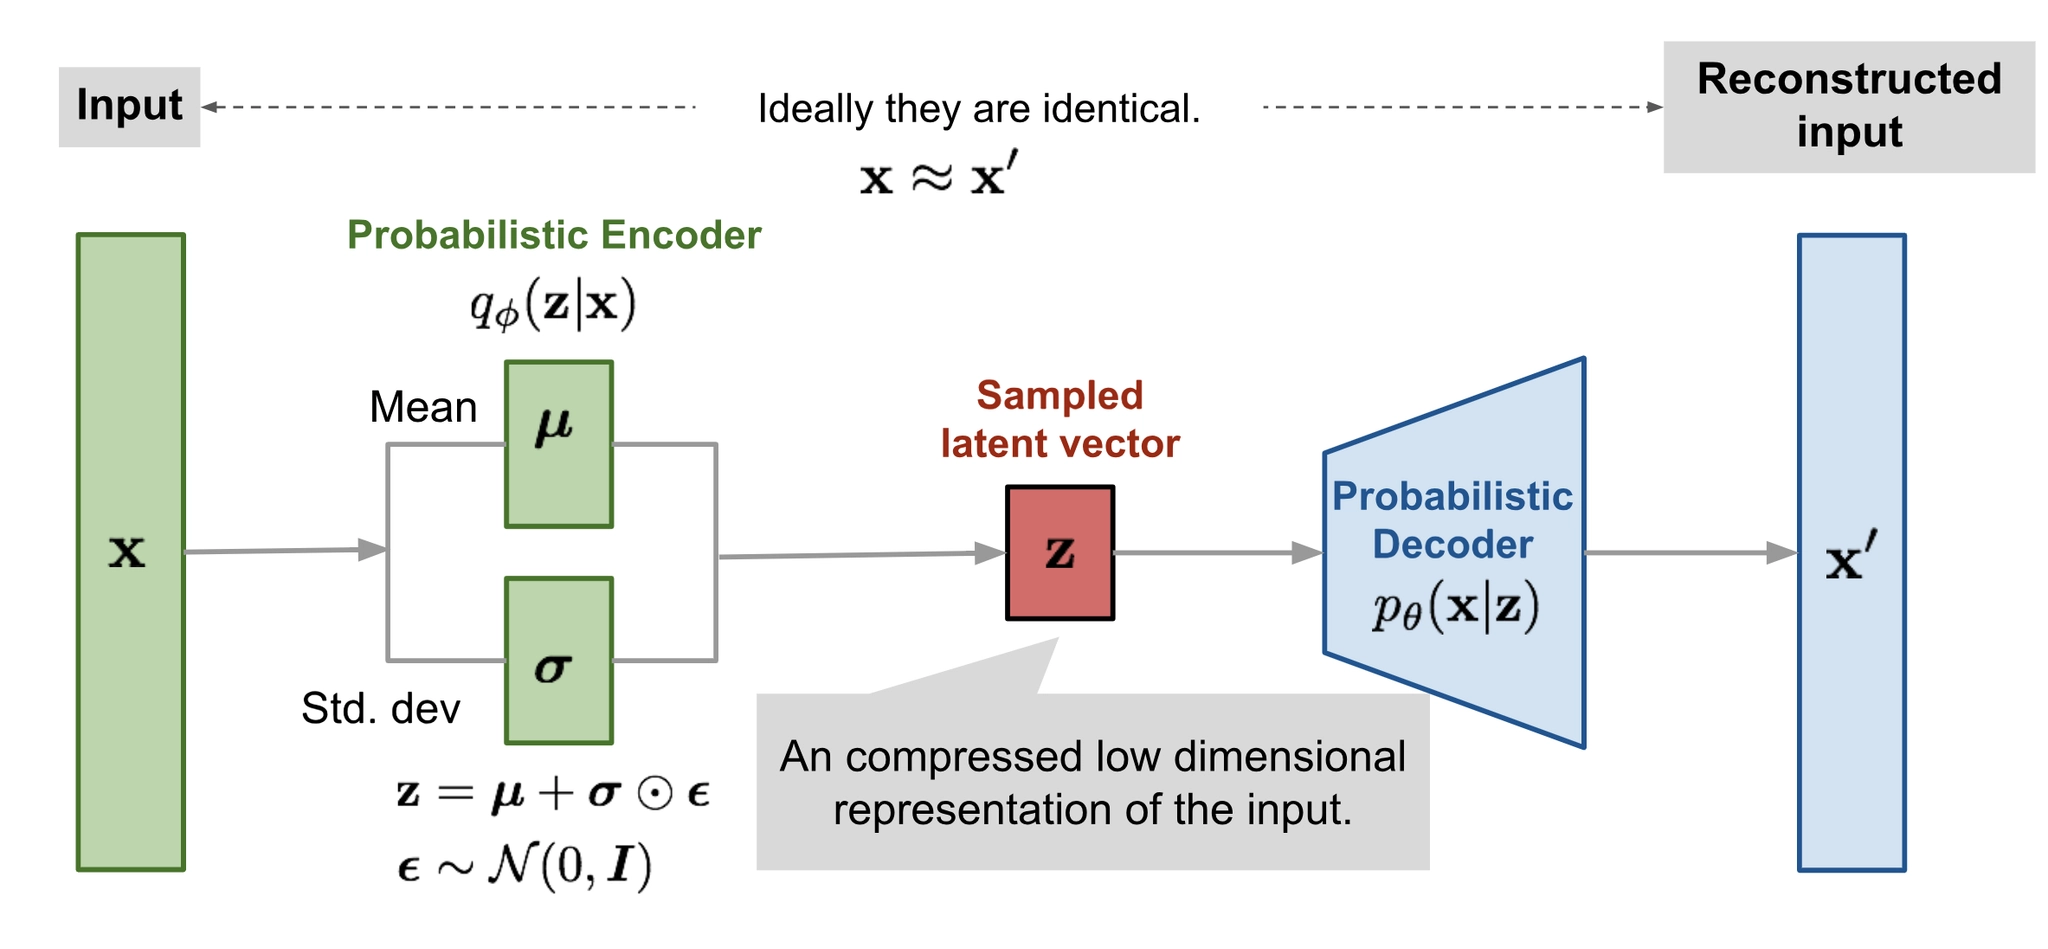

1. **분포 예측 (Probabilistic Encoder)**
    - 인코더 $q_\phi(z|x)$ 가 입력 x를 보고 평균 μ와 표준편차 σ를 예측
    - 고정된 벡터가 아니라 분포를 예측하니까 하나의 데이터에서도 조금씩 다른 z를 뽑을 수 있음
2. **샘플링 및 재파라미터화 (Reparameterization Trick)**
    - $z = \mu + \sigma \odot \varepsilon$,  $\varepsilon \sim \mathcal{N}(0, I)$
    - 그냥 무작위 샘플링을 하면 기울기를 전달할 수 없어서 학습이 안 됨 → <mark style="background-color:#D6EEFF">무작위성을 노이즈 ε로 따로 분리해서 학습 가능하게 만듦</mark>
    - ex. μ = 2, σ = 0.5일 때 ε = 1이면 z = 2.5, ε = -1이면 z = 1.5 → 노이즈에 따라 다른 z
3. **생성 (Probabilistic Decoder)**
    - 디코더 $p_\theta(x|z)$ 가 z로 데이터를 복원하거나 생성
    - 학습 중: 원본 x와 복원 x'가 비슷해지도록 학습
    - 학습 후: 표준정규분포에서 새 z를 뽑아 디코더에 넣으면 **입력 없이도** 학습 데이터에 없던 새로운 데이터 생성

### (4) GAN (Generative Adversarial Network)
- <mark style="background-color:#D6EEFF">생성자(G)와 판별자(D) 두 신경망이 **서로 경쟁**하면서 실제와 비슷한 새 데이터를 생성하도록 학습하는 모델</mark> (2014, Ian Goodfellow)
- 위조지폐범과 경찰 비유
    - 범인(생성자): 경찰을 속이려고 점점 더 정교한 위조지폐를 만듦
    - 경찰(판별자): 진짜/가짜 감별 능력을 계속 키움
    - 최적점: 생성자는 진짜와 구분 불가능한 데이터를 만들고, 판별자는 찍어서 맞히는 수준(확률 0.5)이 됨

#### [구조]

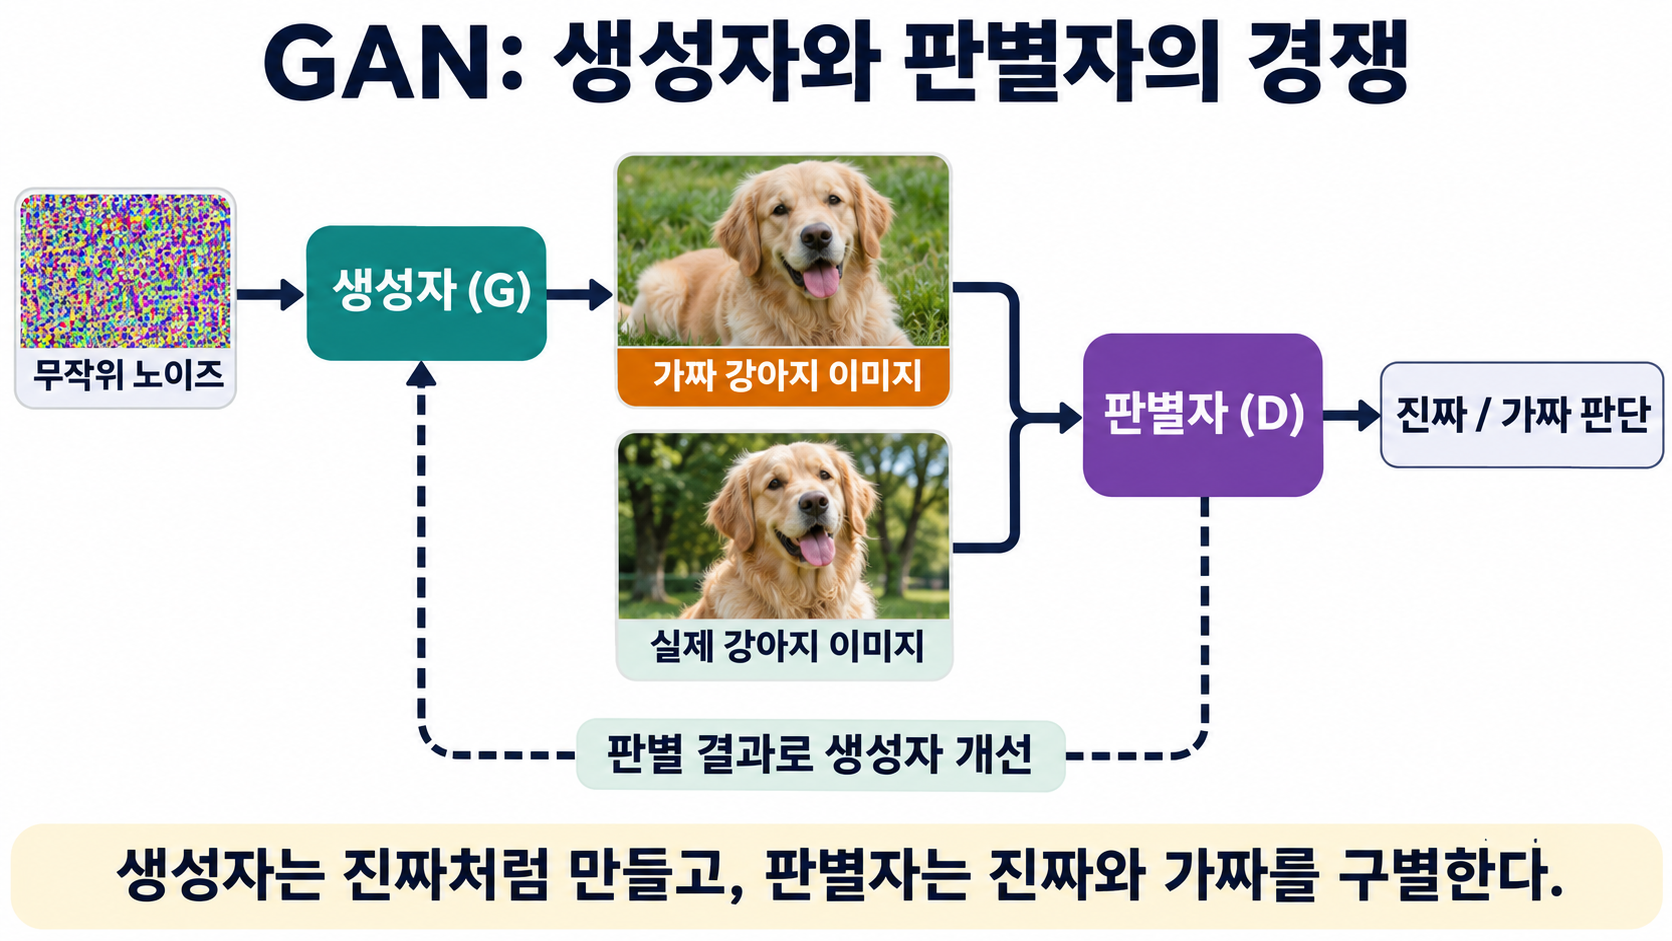

1. 무작위 노이즈 z: 생성자에 들어가는 무작위 숫자 벡터
2. 생성자 G: z를 받아 가짜 이미지 G(z) 생성 → 판별자가 진짜라고 믿게 만드는 게 목표
3. 판별자 D: 실제 이미지 x 또는 가짜 G(z)를 받아 진짜일 확률(0~1) 출력 → 정확하게 구별하는 게 목표
    - ex. D(x) = 0.9 (진짜를 진짜로), D(G(z)) = 0.1 (가짜를 가짜로)

#### [최소-최대 게임 (Minimax Game)]
- 판별자: 진짜는 1, 가짜는 0에 가깝게 출력하도록 구별 능력을 **최대화**
- 생성자: 판별자가 구별하지 못하도록, 즉 판별자의 능력을 **최소화**
- 반복 학습: 처음엔 가짜에 10%를 주던 판별자가 생성자 개선 후 80%를 줌 → 판별자도 다시 학습 → …
- 학습이 끝나면 생성자만 가져와서 새로운 데이터 생성에 사용

#### [장점]
- 진짜 같은 가짜 생성: 실제엔 없지만 진짜처럼 보이는 데이터 생성 (ex. 실존하지 않는 사람 얼굴)
- 높은 선명도: VAE는 픽셀 평균(MSE)을 최적화해서 흐릿해지지만, GAN은 판별자를 속여야 하니까 미세한 질감까지 살아남
- 빠른 생성 속도: 학습 후엔 노이즈를 생성자에 **한 번만** 통과시키면 됨 (확산 모델보다 빠름)
- 부드러운 잠재 공간: 잠재 벡터를 조금씩 바꾸면 이미지 특징도 자연스럽게 변함 (단, 항상 보장되진 않음)

#### [한계]
- **학습 불안정성**: 생성자와 판별자가 반대 목표로 동시에 학습해서 균형이 쉽게 무너짐 → 진동, 수렴 실패
    - 해결: 학습률·업데이트 횟수 조절, WGAN-GP
- **훈련 초기 문제**: 초반엔 생성자가 너무 못해서 판별자가 쉽게 구별 → 생성자에 가는 기울기가 거의 0
    - 해결: Non-saturating Loss, 판별자 학습 속도 조절
- **모드 붕괴 (Mode Collapse)**: <mark style="background-color:#D6EEFF">판별자를 잘 속이는 특정 유형만 반복 생성 → 다양성 감소</mark> (ex. 비슷한 강아지만 계속 생성)
    - 해결: Minibatch Discrimination, WGAN-GP
- **평가 지표의 한계**: 사실성, 선명도, 다양성을 하나의 지표로 평가하기 어려움
    - 해결: FID(실제·생성 이미지 특징 분포 비교), IS(분류 확신도 + 다양성), 사람의 평가 병행
- **역매핑의 어려움**: z → 이미지 단방향 구조라서, 실제 이미지에 해당하는 z를 찾기 어려움
    - 해결: GAN Inversion, BiGAN(인코더 추가)

#### [적용 사례]
- NVIDIA Progressive GAN: 저해상도 → 고해상도로 점진적으로 키우며 학습해서, 실존하지 않는 고해상도 인물 얼굴 생성
- Deep Video Portraits (Conditional GAN): A의 표정·머리 움직임·시선을 B의 영상에 자연스럽게 반영
- Facebook Eye In-Painting (Exemplar GAN): 같은 사람의 눈 뜬 참고 사진을 활용해 눈 감은 사진을 자연스럽게 복원

### (5) 확산 모델 (Diffusion Model)
- 이미지에 노이즈를 추가한 데이터로 학습하고, <mark style="background-color:#D6EEFF">**무작위 노이즈를 단계적으로 제거하면서** 새로운 이미지를 생성하는 모델</mark>
- 목표: 실제 데이터의 분포를 학습해서 자연스럽고 다양한 데이터를 생성
- **모호성 모델링**: 하나의 조건에서도 여러 결과가 가능하다는 불확실성을 확률분포로 표현
    - ex. "공원에 앉아 있는 강아지" → 품종, 털색, 자세, 배경이 다른 여러 이미지 생성 가능
- 활용: 이미지 생성·복원·편집, 영상 생성

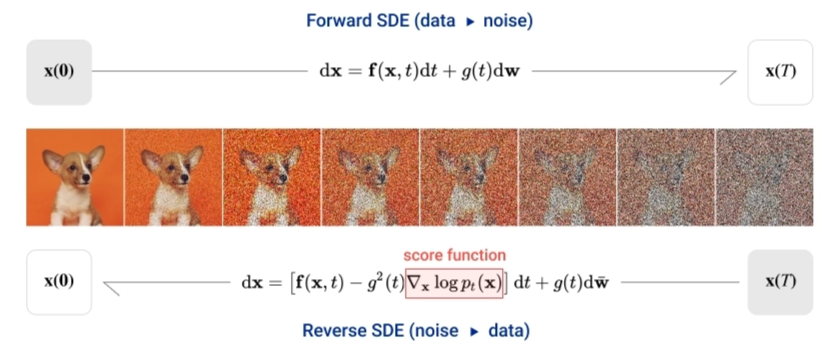

- 위: 순확산 (데이터 → 노이즈), 아래: 역확산 (노이즈 → 데이터)

#### [순확산 (Forward Diffusion)]
- 원본 이미지 x₀에 **가우시안 노이즈**(정규분포를 따르는 무작위 잡음)를 조금씩 추가하는 과정
- x₀ → x₁ → x₂ → … → x_T
- 단계가 진행될수록 노이즈가 누적돼서 윤곽이 사라지고, 결국 무작위 노이즈 x_T가 됨
- 목적: 다양한 수준의 노이즈 낀 데이터를 만들어서, 역확산에서 노이즈 제거 방법을 학습할 재료로 씀

#### [역확산 (Reverse Diffusion)]
- 순확산의 반대 방향: 무작위 노이즈 x_T에서 시작해서 노이즈를 단계적으로 제거하는 과정
- x_T → … → x₁ → x₀
- **Denoising U-Net**이 현재 이미지에 낀 노이즈를 예측하고, 그만큼 조금씩 제거하는 걸 반복
- 반복할수록 색상과 윤곽이 드러나고, 최종적으로 새로운 이미지 x₀ 생성

→ <mark style="background-color:#D6EEFF">학습은 순확산으로 만든 데이터로 "노이즈 예측"을 배우고, 생성은 역확산으로 함</mark>

#### [장점]
- 높은 샘플 품질: 한 번에 생성하는 GAN과 달리 단계적으로 다듬어서 더 정교하고 사실적인 이미지 생성
- 학습 안정성: 경쟁 구조가 아니라 실제 노이즈와 예측 노이즈의 차이(MSE)만 줄이면 됨 → 손실 곡선으로 학습 상황 확인 가능
- 다양성: 무작위 노이즈에서 시작하니까 같은 조건에서도 다른 결과 생성 (모드 붕괴 문제 적음)

#### [단점]
- 느린 생성 속도: 노이즈 제거를 여러 단계 반복해야 해서 GAN보다 훨씬 느림
- 높은 계산 비용: 학습·생성 모두 신경망을 반복 실행 → 고성능 GPU 필요
- 구조적 제약: 단계 수나 노이즈 제거 방식에 따라 속도와 품질이 달라져서 설계가 까다로움